# AdaBoost Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md).
Every lab is **self-contained**: a short goal, the code, the picture/numbers, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports). After that run the labs in order (`Shift + Enter` cell by cell),
   or **Run All**. Labs only reuse data from *earlier* cells, so running top-to-bottom always works.
2. Look at the output and **guess what it means before you read the "How to read this" box**.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

| Part | Labs | What it proves |
|---|---|---|
| **A. How AdaBoost works** | 1 – 5 | The hand example number by number; how the weights move; how the boundary is built; the training-error bound; margins |
| **B. Why it is useful** | 6 – 9 | Stumps → a strong model; base-tree depth; `learning_rate` × `n_estimators`; more than two classes (SAMME) |
| **C. Where it fails (and why)** | 10 – 15 | Noisy labels (the bad-fit data), outliers, a too-strong and a too-weak base learner, bad probabilities, sequential cost |

All data is generated in the notebook (or ships inside scikit-learn: `load_digits`) — **no internet needed**.
The two generated datasets are also saved to `data/` so the from-scratch notebook can use exactly the same rows.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.datasets import load_digits
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

DATA = Path("data")
DATA.mkdir(exist_ok=True)


def stump_ada(n_estimators, learning_rate=1.0, depth=1):
    """AdaBoost with decision trees of the given depth (depth=1: stumps, the default base learner)."""
    return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth),
                              n_estimators=n_estimators, learning_rate=learning_rate, random_state=0)


def staged_errors(model, X, y):
    """Error rate after 1, 2, ..., M rounds (one number per round)."""
    return np.array([np.mean(pred != y) for pred in model.staged_predict(X)])


def cv_staged_error(make_model, X, y, n_splits=5):
    """Mean cross-validated error after every round, from ONE fit per fold (uses staged_predict)."""
    curves = []
    for tr, va in StratifiedKFold(n_splits, shuffle=True, random_state=0).split(X, y):
        curves.append(staged_errors(make_model().fit(X[tr], y[tr]), X[va], y[va]))
    m = min(len(c) for c in curves)          # a fold may stop early
    return np.mean([c[:m] for c in curves], axis=0)


def replay_weights(ada, X, y):
    """The sample weights AdaBoost used to fit each round, replayed from the fitted model
    (same steps as scikit-learn: clip tiny weights, multiply the misclassified by e^alpha, normalise)."""
    w, tiny, used = np.full(len(y), 1 / len(y)), np.finfo(float).eps, []
    for est, alpha in zip(ada.estimators_, ada.estimator_weights_):
        w = np.clip(w, tiny, None)
        used.append(w.copy())
        w = w * np.exp(alpha * (est.predict(X) != y))
        w = w / w.sum()
    return np.array(used)


GRID = np.linspace(-1.05, 1.05, 211)
GX1, GX2 = np.meshgrid(GRID, GRID)
GRID_POINTS = np.column_stack([GX1.ravel(), GX2.ravel()])


def plot_regions(ax, labels, title):
    """Colour the plane by predicted class (labels = predictions on GRID_POINTS)."""
    ax.contourf(GX1, GX2, labels.reshape(GX1.shape), levels=[-0.5, 0.5, 1.5, 2.5],
                colors=["#9ecae1", "#fdae6b", "#a1d99b"], alpha=0.6)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal")
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.set_xticks([]); ax.set_yticks([])


def draw_circle(ax, r=np.sqrt(2 / np.pi)):
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(r * np.cos(t), r * np.sin(t), "k--", lw=1)

---
# The two datasets

Both datasets have **two features** `x1, x2` (uniform in the square [−1, 1]², rounded to 3 decimals like a real
measuring device, so some values repeat) and a **class** `y` ∈ {0, 1}.

* **Good fit — `make_good_fit`:** `y = 1` inside a circle of radius √(2/π) ≈ 0.80 (chosen so the two classes are about
  equally big), `y = 0` outside. No label noise. A single cut along `x1` or `x2` (a *stump*) is a poor model of a circle,
  but the circle rule `x1² + x2² < r²` is a **sum of one part per feature** (`x1²` + `x2²`), which is exactly the kind of
  rule a weighted sum of stumps can build. AdaBoost should shine here.
* **Bad fit — `make_bad_fit`:** the **same 1000 points and the same circle**, but exactly 20 % of the labels (200 rows,
  picked at random) are **flipped**. AdaBoost keeps raising the weight of whatever it gets wrong — and a mislabeled point
  is wrong *forever*. README §8.1 predicts trouble.

Both functions save a CSV to `data/` (header `x1,x2,y`). The same train/test split (70 % / 30 %, `random_state=0`) is
used for both, so test rows are the same points in both datasets.

good fit: 1000 rows, share of class 1 = 0.496
bad fit : 1000 rows, flipped labels = 200 (20%), rows that differ from good fit = 200
train / test rows: 700 / 300;  flipped among train = 145, among test = 55
  data/good_fit.csv: 14.8 kB
  data/bad_fit.csv: 14.8 kB


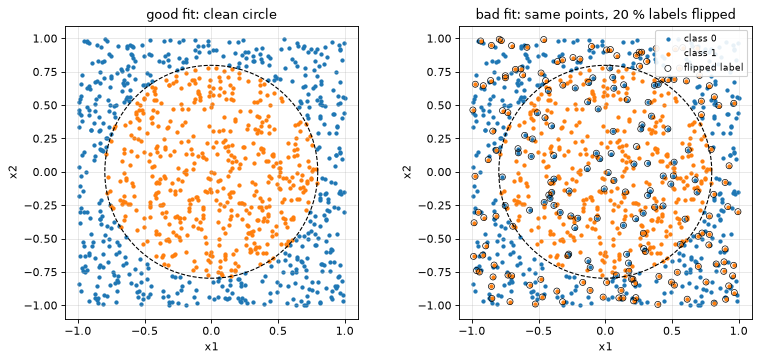

In [2]:
def make_good_fit(seed=0, n=1000):
    """Points uniform in [-1, 1]^2; class 1 inside the circle x1^2 + x2^2 < 2/pi (about half the square)."""
    rng = np.random.default_rng(seed)
    X = np.round(rng.uniform(-1, 1, size=(n, 2)), 3)
    y = (X[:, 0] ** 2 + X[:, 1] ** 2 < 2 / np.pi).astype(int)
    np.savetxt(DATA / "good_fit.csv", np.column_stack([X, y]), delimiter=",",
               header="x1,x2,y", comments="", fmt="%.6g")
    return X, y


def make_bad_fit(seed=0, flip_fraction=0.2):          # <- try changing flip_fraction
    """The good-fit points, with exactly flip_fraction of the labels flipped at random."""
    X, y_clean = make_good_fit(seed)
    rng = np.random.default_rng(seed + 1)
    flipped = np.zeros(len(y_clean), dtype=bool)
    flipped[rng.permutation(len(y_clean))[: int(flip_fraction * len(y_clean))]] = True
    y = np.where(flipped, 1 - y_clean, y_clean)
    np.savetxt(DATA / "bad_fit.csv", np.column_stack([X, y]), delimiter=",",
               header="x1,x2,y", comments="", fmt="%.6g")
    return X, y, flipped


X_good, y_good = make_good_fit()
X_bad, y_bad, flipped = make_bad_fit()
idx_train, idx_test = train_test_split(np.arange(len(y_good)), test_size=0.3, random_state=0)

Xtr, Xte = X_good[idx_train], X_good[idx_test]           # the SAME points in both datasets
ytr_good, yte_good = y_good[idx_train], y_good[idx_test]
ytr_bad, yte_bad = y_bad[idx_train], y_bad[idx_test]
flip_tr = flipped[idx_train]

print(f"good fit: {len(y_good)} rows, share of class 1 = {y_good.mean():.3f}")
print(f"bad fit : {len(y_bad)} rows, flipped labels = {flipped.sum()} ({flipped.mean():.0%}), "
      f"rows that differ from good fit = {(y_bad != y_good).sum()}")
print(f"train / test rows: {len(idx_train)} / {len(idx_test)};  flipped among train = {flip_tr.sum()}, among test = {flipped[idx_test].sum()}")
for f in ["good_fit.csv", "bad_fit.csv"]:
    print(f"  data/{f}: {(DATA / f).stat().st_size / 1e3:.1f} kB")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, y, title in [(axes[0], y_good, "good fit: clean circle"), (axes[1], y_bad, "bad fit: same points, 20 % labels flipped")]:
    ax.scatter(*X_good[y == 0].T, s=8, c="tab:blue", label="class 0")
    ax.scatter(*X_good[y == 1].T, s=8, c="tab:orange", label="class 1")
    draw_circle(ax); ax.set_aspect("equal"); ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
axes[1].scatter(*X_good[flipped].T, s=30, facecolors="none", edgecolors="k", lw=0.6, label="flipped label")
axes[1].legend(loc="upper right", fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: orange inside the dashed circle, blue outside, about half of each (share of class 1 = 0.496).
> * Right: the very same points, but 200 of them (circled) now carry the wrong colour. No model can be right about those
>   on new data either, so the best possible test error on the bad-fit data is about the flip rate: 55 of the 300 test rows
>   (18.3 %) are flipped.

---
# Part A — How AdaBoost works

## Lab 1 · The hand-worked example, done by the computer

**Goal:** reproduce README §5 number by number. Eight points on a line, `x = 1 … 8`, labels `+ + + + − − + −`.
Three rounds of AdaBoost with stumps of the form “if `x ≤ t` predict one class, else the other”.
First we do it the **textbook** way (labels ±1, stage value α = ½ ln((1−ε)/ε), weights × e^(±α)); then we let
scikit-learn do it and check that it gets the same stumps, the same weights and the same final vote.

In [3]:
x_hand = np.arange(1, 9, dtype=float)
y_hand = np.array([1, 1, 1, 1, -1, -1, 1, -1])
thresholds = x_hand[:-1] + 0.5                       # cut points 1.5, 2.5, ..., 7.5


def weighted_gini_of_split(w, y, left):
    """W_L * Gini_L + W_R * Gini_R : the weighted impurity a tree minimises (README §2.4)."""
    total = 0.0
    for side in (left, ~left):
        W = w[side].sum()
        shares = np.array([w[side & (y == c)].sum() for c in (-1, 1)]) / W
        total += W * (1 - np.sum(shares ** 2))
    return total


w = np.full(8, 1 / 8)                                  # step 1: equal weights 1/N
F_hand, alphas_hand, eps_hand = np.zeros(8), [], []
for m in range(1, 4):
    rows = []
    for t in thresholds:                               # step 2: try every cut; each side predicts its heavier class
        left = x_hand <= t
        side = [1 if w[s & (y_hand == 1)].sum() > w[s & (y_hand == -1)].sum() else -1 for s in (left, ~left)]
        h = np.where(left, side[0], side[1])
        rows.append((weighted_gini_of_split(w, y_hand, left), np.sum(w[h != y_hand]), t, h))
    gini, eps, t, h = min(rows, key=lambda r: r[0])    # keep the cut with the lowest weighted Gini
    alpha = 0.5 * np.log((1 - eps) / eps)              # step 4: stage value
    if m == 1:
        print("round 1, every cut:  t   weighted error   weighted Gini")
        for g, e, tt, _ in rows:
            print(f"                  {tt}      {e:.4f}         {g:.4f}")
    print(f"\nROUND {m}: weights = {w.round(4)}")
    print(f"  best stump: x <= {t} -> {h[0]:+d}, else {h[-1]:+d};  misclassified x = {x_hand[h != y_hand].astype(int)}")
    print(f"  weighted error eps = {eps:.4f}   stage value alpha = 0.5*ln((1-eps)/eps) = {alpha:.4f}")
    F_hand += alpha * h; alphas_hand.append(alpha); eps_hand.append(eps)
    w = w * np.exp(-alpha * y_hand * h)                # step 5: wrong x e^alpha, right x e^-alpha
    w = w / w.sum()                                    # step 6: normalise

print("\nfinal score F(x) = sum alpha_m h_m(x):", F_hand.round(3))
print("prediction sign(F):", np.sign(F_hand).astype(int), "  true labels:", y_hand, "  all correct:", np.all(np.sign(F_hand) == y_hand))
print(f"training-error bound prod 2 sqrt(eps(1-eps)) = {np.prod([2 * np.sqrt(e * (1 - e)) for e in eps_hand]):.4f};"
      f"  average exp-loss mean(exp(-y F)) = {np.mean(np.exp(-y_hand * F_hand)):.4f}")

round 1, every cut:  t   weighted error   weighted Gini
                  1.5      0.3750         0.4286
                  2.5      0.3750         0.3750
                  3.5      0.2500         0.3000
                  4.5      0.1250         0.1875
                  5.5      0.2500         0.3667
                  6.5      0.3750         0.4583
                  7.5      0.2500         0.3571

ROUND 1: weights = [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
  best stump: x <= 4.5 -> +1, else -1;  misclassified x = [7]
  weighted error eps = 0.1250   stage value alpha = 0.5*ln((1-eps)/eps) = 0.9730

ROUND 2: weights = [0.071 0.071 0.071 0.071 0.071 0.071 0.5   0.071]
  best stump: x <= 7.5 -> +1, else -1;  misclassified x = [5 6]
  weighted error eps = 0.1429   stage value alpha = 0.5*ln((1-eps)/eps) = 0.8959

ROUND 3: weights = [0.042 0.042 0.042 0.042 0.25  0.25  0.292 0.042]
  best stump: x <= 6.5 -> -1, else +1;  misclassified x = [1 2 3 4 8]
  weighted error eps = 0.2083   s

In [4]:
sk_hand = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=3, random_state=0)
sk_hand.fit(x_hand.reshape(-1, 1), y_hand)
w_sk = replay_weights(sk_hand, x_hand.reshape(-1, 1), y_hand)

print("scikit-learn thresholds     :", [est.tree_.threshold[0] for est in sk_hand.estimators_])
print("scikit-learn errors (eps)   :", sk_hand.estimator_errors_)
print("scikit-learn weights        :", sk_hand.estimator_weights_)
print("textbook alphas x 2         :", 2 * np.array(alphas_hand))
print("ln 7, ln 6, ln(19/5)        :", np.log([7, 6, 19 / 5]))
print("weights used in round 3 (sklearn replay):", w_sk[2].round(4), "  x 24 =", (24 * w_sk[2]).round(3))
print("sklearn decision_function   :", sk_hand.decision_function(x_hand.reshape(-1, 1)).round(3))
print("2 x F / sum(alpha)          :", (2 * F_hand / np.sum(alphas_hand)).round(3))
print("sklearn predict             :", sk_hand.predict(x_hand.reshape(-1, 1)))

scikit-learn thresholds     : [np.float64(4.5), np.float64(7.5), np.float64(6.5)]
scikit-learn errors (eps)   : [0.125 0.143 0.208]
scikit-learn weights        : [1.946 1.792 1.335]
textbook alphas x 2         : [1.946 1.792 1.335]
ln 7, ln 6, ln(19/5)        : [1.946 1.792 1.335]
weights used in round 3 (sklearn replay): [0.042 0.042 0.042 0.042 0.25  0.25  0.292 0.042]   x 24 = [1. 1. 1. 1. 6. 6. 7. 1.]
sklearn decision_function   : [ 0.947  0.947  0.947  0.947 -0.587 -0.587  0.466 -0.947]
2 x F / sum(alpha)          : [ 0.947  0.947  0.947  0.947 -0.587 -0.587  0.466 -0.947]
sklearn predict             : [ 1  1  1  1 -1 -1  1 -1]


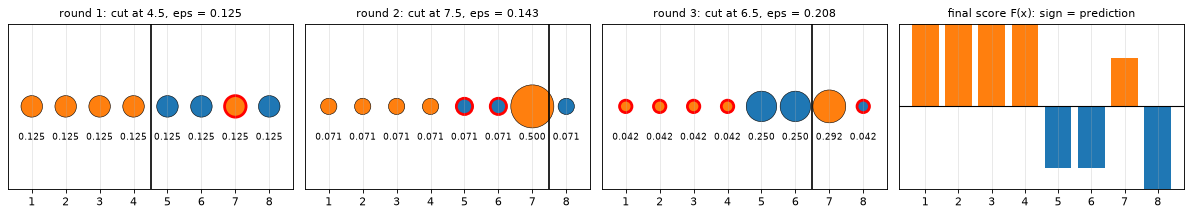

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 2.8), sharey=True)
w_plot = replay_weights(sk_hand, x_hand.reshape(-1, 1), y_hand)
for m, ax in enumerate(axes[:3]):
    est = sk_hand.estimators_[m]
    t = est.tree_.threshold[0]
    colors = np.where(y_hand == 1, "tab:orange", "tab:blue")
    wrong = est.predict(x_hand.reshape(-1, 1)) != y_hand
    ax.scatter(x_hand, np.zeros(8), s=3000 * w_plot[m], c=colors, edgecolors=np.where(wrong, "red", "k"), linewidths=np.where(wrong, 2.5, 0.5))
    ax.axvline(t, color="k", lw=1.5)
    for xi, wi in zip(x_hand, w_plot[m]):
        ax.annotate(f"{wi:.3f}", (xi, 0), xytext=(0, -30), textcoords="offset points", ha="center", fontsize=8)
    ax.set_title(f"round {m + 1}: cut at {t}, eps = {sk_hand.estimator_errors_[m]:.3f}", fontsize=10)
    ax.set_ylim(-1, 1); ax.set_xlim(0.3, 8.7); ax.set_yticks([]); ax.set_xticks(x_hand)
axes[3].bar(x_hand, F_hand, color=np.where(F_hand > 0, "tab:orange", "tab:blue"))
axes[3].axhline(0, color="k", lw=1); axes[3].set_xticks(x_hand)
axes[3].set_title("final score F(x): sign = prediction", fontsize=10)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Round 1** (all weights 1/8 = 0.125): the cut `x ≤ 4.5 → +` has the lowest weighted Gini (0.1875) *and* the lowest
>   error (one mistake, x = 7): ε₁ = 1/8 = 0.125, α₁ = ½ ln 7 = 0.9730.
> * **Round 2:** the one mistake (x = 7) now holds half of all weight (0.5); the other seven hold 1/14 = 0.071 each.
>   The best stump moves to `x ≤ 7.5 → +`, which gets x = 7 right and x = 5, 6 wrong: ε₂ = 2/14 = 0.1429, α₂ = ½ ln 6 = 0.8959.
> * **Round 3:** weights are 1/24 = 0.042 (x = 1–4, 8), 6/24 = 0.25 (x = 5, 6) and 7/24 = 0.292 (x = 7). The stump `x ≤ 6.5 → −`
>   wins with ε₃ = 5/24 = 0.2083, α₃ = ½ ln(19/5) = 0.6675.
> * Final score F = 1.201 (x = 1–4), −0.745 (x = 5, 6), +0.590 (x = 7), −1.201 (x = 8): **all eight points are right**,
>   although each single stump got one to five of them wrong. The training-error bound ∏ 2√(ε(1−ε)) = 0.376 equals the average
>   exponential loss, as README §4.4 says.
> * scikit-learn finds the **same cuts and the same ε**, but its stage values are ln 7 = 1.946, ln 6 = 1.792, ln(19/5) = 1.335 —
>   exactly **2× the textbook α** (it uses the SAMME formula, README §4.6). The weights it uses in round 3 are the same
>   1/24, 6/24, 7/24 (×24 = 1, 6, 7), and its `decision_function` is 2F / Σα: same sign, so the same predictions.

## Lab 2 · Watch the weights move

**Goal:** see the “focus on the hard cases” idea. We fit AdaBoost with stumps to the good-fit training data and draw
every training point with a **size proportional to its weight** in rounds 1, 2, 3, 10, 50 and 300, plus the stump fitted in that
round (black line). README §3, step 5.

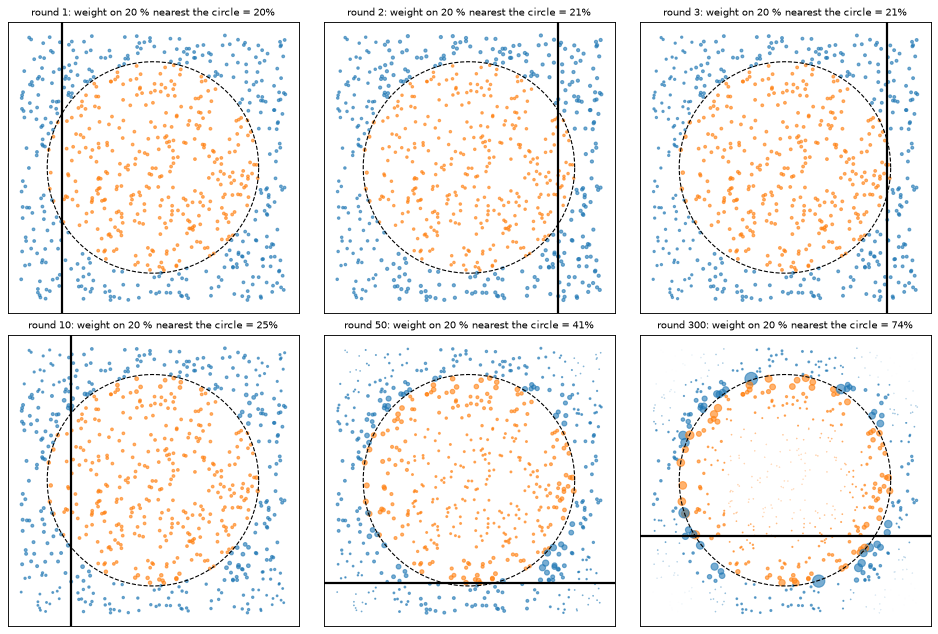

round    1: weight on the 20 % of points nearest the circle = 0.200;  largest single weight = 0.0014 (equal share would be 0.0014)
round    2: weight on the 20 % of points nearest the circle = 0.206;  largest single weight = 0.0019 (equal share would be 0.0014)
round    3: weight on the 20 % of points nearest the circle = 0.206;  largest single weight = 0.0023 (equal share would be 0.0014)
round   10: weight on the 20 % of points nearest the circle = 0.247;  largest single weight = 0.0026 (equal share would be 0.0014)
round   50: weight on the 20 % of points nearest the circle = 0.408;  largest single weight = 0.0083 (equal share would be 0.0014)
round  300: weight on the 20 % of points nearest the circle = 0.743;  largest single weight = 0.0313 (equal share would be 0.0014)
round 1000: weight on the 20 % of points nearest the circle = 0.898;  largest single weight = 0.0480 (equal share would be 0.0014)


In [6]:
ada_good = stump_ada(1000).fit(Xtr, ytr_good)
W_good = replay_weights(ada_good, Xtr, ytr_good)                 # (rounds, points)
r_train = np.sqrt((Xtr ** 2).sum(axis=1))
near_boundary = np.abs(r_train - np.sqrt(2 / np.pi)) < np.quantile(np.abs(r_train - np.sqrt(2 / np.pi)), 0.2)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, m in zip(axes.ravel(), [1, 2, 3, 10, 50, 300]):
    est = ada_good.estimators_[m - 1]
    f, t = est.tree_.feature[0], est.tree_.threshold[0]
    ax.scatter(*Xtr.T, s=W_good[m - 1] * len(Xtr) * 6, c=np.where(ytr_good == 1, "tab:orange", "tab:blue"), alpha=0.6)
    (ax.axvline if f == 0 else ax.axhline)(t, color="k", lw=2)
    draw_circle(ax)
    ax.set_title(f"round {m}: weight on 20 % nearest the circle = {W_good[m - 1][near_boundary].sum():.0%}", fontsize=9)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

for m in [1, 2, 3, 10, 50, 300, 1000]:
    w_m = W_good[m - 1]
    print(f"round {m:4d}: weight on the 20 % of points nearest the circle = {w_m[near_boundary].sum():.3f};"
          f"  largest single weight = {w_m.max():.4f} (equal share would be {1 / len(w_m):.4f})")

> **How to read this**
> * Round 1: all points are the same size (weight 1/700). The 20 % of points closest to the circle hold 20 % of the weight.
> * After a few rounds the points far from the circle shrink (almost every stump gets them right) and the points **along the
>   circle** grow: their share is 25 % at round 10, 41 % at round 50, 74 % at round 300 and 90 % at round 1000. The heaviest
>   single point weighs 0.048 at round 1000 — 34 times its starting weight.
> * Each new stump (black line) is fitted to *these* weights, so it is pulled towards the part of the boundary that
>   the current ensemble gets wrong. That is the whole “adaptive” in *Adaptive Boosting*.

## Lab 3 · How the boundary is built from straight cuts

**Goal:** see the weighted sum of stumps turn into a circle. One model with 1000 rounds; we look at its prediction
after 1, 3, 10, 30, 100 and 1000 rounds (`staged_predict` gives every intermediate model without refitting).

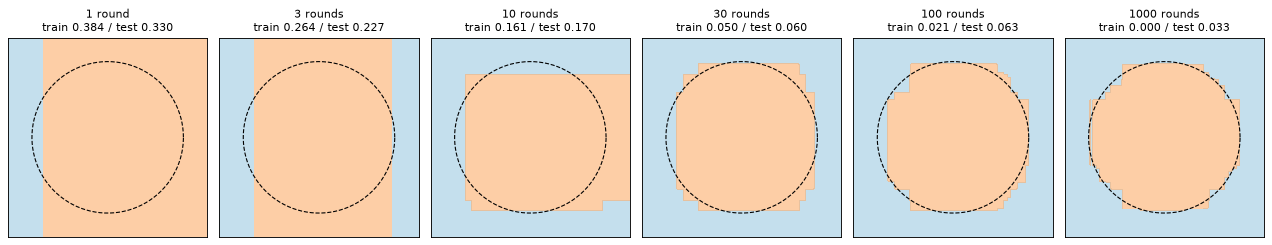

rounds     : [1, 3, 10, 30, 100, 1000]
train error: [0.384 0.264 0.161 0.05  0.021 0.   ]
test error : [0.33  0.227 0.17  0.06  0.063 0.033]


In [7]:
stages_to_show = [1, 3, 10, 30, 100, 1000]
grid_stages = list(ada_good.staged_predict(GRID_POINTS))
err_tr, err_te = staged_errors(ada_good, Xtr, ytr_good), staged_errors(ada_good, Xte, yte_good)

fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, m in zip(axes, stages_to_show):
    plot_regions(ax, grid_stages[m - 1], f"{m} round{'s' if m > 1 else ''}\ntrain {err_tr[m-1]:.3f} / test {err_te[m-1]:.3f}")
    draw_circle(ax)
plt.tight_layout(); plt.show()
print("rounds     :", stages_to_show)
print("train error:", err_tr[np.array(stages_to_show) - 1])
print("test error :", err_te[np.array(stages_to_show) - 1])

> **How to read this**
> * Round 1 is a single stump: one vertical cut, orange on one side, blue on the other (test error 0.330).
> * Every stump adds “+α on one side of a line, −α on the other”. Summed up, these steps form a staircase that hugs the
>   dashed circle more closely the more rounds you add: test error 0.330 → 0.170 (10 rounds) → 0.063 (100) → 0.033 (1000).
> * Every edge of the orange region is horizontal or vertical: a sum of stumps can only build **axis-aligned** steps.
>   That is fine for a circle (README §7) but would need very many steps for a tilted straight boundary.

## Lab 4 · Training error, test error, and the theoretical bound

**Goal:** check README §4.4: the training error after M rounds is at most ∏ 2√(ε_m(1 − ε_m)), and the average
exponential loss on the training set is *exactly* that product (when α is the optimal ½ ln((1−ε)/ε), i.e. `learning_rate=1`).

rounds: [1, 10, 100, 1000]
training error       : [0.384 0.161 0.021 0.   ]
bound prod 2sqrt(e(1-e)): [0.973 0.729 0.188 0.016]
exp-loss on training : [0.973 0.729 0.188 0.016]
max |exp-loss - bound| over all rounds = 2.22e-16
training error first hits 0 at round 446; test error then = 0.030, at round 1000 = 0.033
weighted error of the stumps: round 1 = 0.384, median over rounds 100-1000 = 0.473


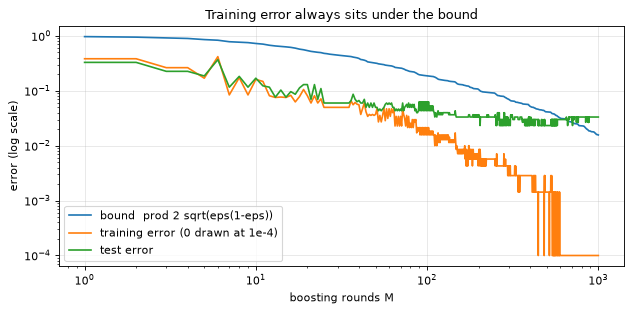

In [8]:
eps_good = ada_good.estimator_errors_[: len(ada_good.estimators_)]
bound = np.cumprod(2 * np.sqrt(eps_good * (1 - eps_good)))
S_m = np.cumsum(ada_good.estimator_weights_)                     # sum of scikit-learn's alphas after m rounds
F_textbook = np.array(list(ada_good.staged_decision_function(Xtr))) * S_m[:, None] / 4   # = sum (alpha/2) h, README 4.6
y_pm = 2 * ytr_good - 1
exp_loss = np.exp(-y_pm * F_textbook).mean(axis=1)            # (1/n) sum exp(-y F) after each round
first_zero = int(np.argmax(err_tr == 0)) + 1 if np.any(err_tr == 0) else None

print("rounds:", [1, 10, 100, 1000])
print("training error       :", err_tr[[0, 9, 99, 999]])
print("bound prod 2sqrt(e(1-e)):", bound[[0, 9, 99, 999]])
print("exp-loss on training :", exp_loss[[0, 9, 99, 999]])
print(f"max |exp-loss - bound| over all rounds = {np.abs(exp_loss - bound).max():.2e}")
print(f"training error first hits 0 at round {first_zero}; test error then = {err_te[first_zero - 1]:.3f}, at round 1000 = {err_te[-1]:.3f}")
print(f"weighted error of the stumps: round 1 = {eps_good[0]:.3f}, median over rounds 100-1000 = {np.median(eps_good[99:]):.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
rounds = np.arange(1, len(err_tr) + 1)
ax.semilogy(rounds, bound, label="bound  prod 2 sqrt(eps(1-eps))")
ax.semilogy(rounds, np.maximum(err_tr, 1e-4), label="training error (0 drawn at 1e-4)")
ax.semilogy(rounds, err_te, label="test error")
ax.set_xlabel("boosting rounds M"); ax.set_ylabel("error (log scale)"); ax.legend(); ax.set_xscale("log")
ax.set_title("Training error always sits under the bound")
plt.tight_layout(); plt.show()

> **How to read this**
> * The blue bound falls steadily (0.973 after 1 round, 0.188 after 100, 0.016 after 1000), and the training error always
>   stays below it. The average exponential loss on the training set equals the bound to floating-point precision (largest gap
>   2.2e-16): the bound *is* the exponential loss, and AdaBoost is driving it down (README §4.3–4.4).
> * Why does the bound keep falling although late stumps are weak? Each round multiplies it by 2√(ε(1−ε)), which is < 1 whenever
>   ε < ½. The stumps here have ε ≈ 0.47 in rounds 100–1000 (median 0.473) — barely better than a coin — yet each still shaves off a bit.
> * The training error first reaches **0** at round 446 (it flickers between 0 and one mistake for a while after that).
>   The test error does **not** shoot up afterwards although the model keeps growing: 0.030 at round 446, 0.033 at round 1000
>   (one more mistake out of 300). Lab 5 looks at what keeps changing once the training error is 0.

## Lab 5 · Margins: why test error can keep falling after training error is 0

**Goal:** README §4.5. The **normalised margin** of a training point is `y · Σ α_m h_m(x) / Σ α_m`, a number in [−1, 1]:
positive = correct, and the bigger, the more *confident* (more of the weighted vote agrees).

On the circle (Lab 4) the test error simply stayed about flat after training error hit 0. To see the textbook effect
we use the data set from *The Elements of Statistical Learning* §10.1 (“nested spheres”), shrunk to 5 features: 
`x` is 5 standard-normal numbers and `y = 1` if `x1² + … + x5²` is above its median (outside a 5-D sphere). Same idea as the
circle, more dimensions. 700 training points, depth-2 base trees, and a **20 000-point** test set so that small changes in
test error are real, not luck.

training error first hits 0 at round 169
  50 rounds: train error 0.034, test error 0.1051, smallest margin -0.057, share with margin < 0.1 = 0.321, 10th percentile = 0.036
 169 rounds: train error 0.000, test error 0.0663, smallest margin +0.001, share with margin < 0.1 = 0.401, 10th percentile = 0.047
 400 rounds: train error 0.000, test error 0.0635, smallest margin +0.025, share with margin < 0.1 = 0.444, 10th percentile = 0.051
 800 rounds: train error 0.000, test error 0.0640, smallest margin +0.039, share with margin < 0.1 = 0.471, 10th percentile = 0.054


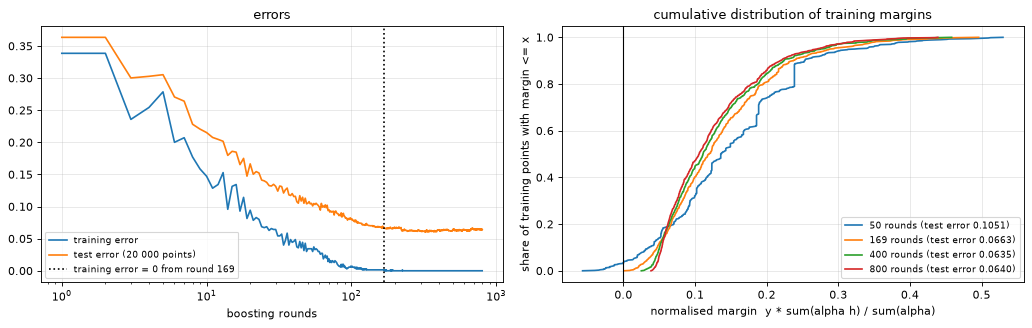

In [9]:
rng = np.random.default_rng(5)
X5 = rng.standard_normal((700 + 20_000, 5))
y5 = (np.sum(X5 ** 2, axis=1) > chi2.ppf(0.5, df=5)).astype(int)     # half the points on each side
X5tr, y5tr, X5te, y5te = X5[:700], y5[:700], X5[700:], y5[700:]

ada5 = stump_ada(800, depth=2).fit(X5tr, y5tr)                      # <- try depth=1 or 3
tr5, te5 = staged_errors(ada5, X5tr, y5tr), staged_errors(ada5, X5te, y5te)
zero5 = int(np.argmax(tr5 == 0)) + 1
dec5 = list(ada5.staged_decision_function(X5tr))                     # sklearn: 2 * sum(alpha h) / sum(alpha)
ypm5 = 2 * y5tr - 1
print(f"training error first hits 0 at round {zero5}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(np.arange(1, 801), tr5, label="training error"); axes[0].plot(np.arange(1, 801), te5, label="test error (20 000 points)")
axes[0].axvline(zero5, color="k", ls=":", label=f"training error = 0 from round {zero5}")
axes[0].set_xscale("log"); axes[0].set_xlabel("boosting rounds"); axes[0].legend(fontsize=8); axes[0].set_title("errors")
for m in [50, zero5, 400, 800]:
    margins = ypm5 * dec5[m - 1] / 2
    axes[1].plot(np.sort(margins), np.linspace(0, 1, len(margins)), label=f"{m} rounds (test error {te5[m - 1]:.4f})")
    print(f"{m:4d} rounds: train error {tr5[m - 1]:.3f}, test error {te5[m - 1]:.4f}, smallest margin {margins.min():+.3f}, "
          f"share with margin < 0.1 = {np.mean(margins < 0.1):.3f}, 10th percentile = {np.quantile(margins, 0.1):.3f}")
axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("normalised margin  y * sum(alpha h) / sum(alpha)"); axes[1].set_ylabel("share of training points with margin <= x")
axes[1].legend(fontsize=8); axes[1].set_title("cumulative distribution of training margins")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: training error reaches 0 at round 169, but the test error **keeps falling** after that: 0.0663 at round 169 →
>   0.0635 at round 400 (56 fewer mistakes on 20 000 new points), then it stays flat (0.0640 at 800).
> * Right: each curve shows, for every margin value on the x-axis, the share of training points with a margin at most that
>   big; everything left of the black line is a training mistake. After round 169 nothing is left of the line, yet the
>   **low end keeps moving right**: the smallest margin rises (+0.001 → +0.025 → +0.039 at rounds 169, 400, 800) and so
>   does the 10th percentile (0.047 → 0.051 → 0.054). The ensemble keeps becoming more *sure* about its hardest training points.
> * The top end moves left at the same time (the share of points with margin < 0.1 grows from 0.401 to 0.471): AdaBoost
>   trades confidence on easy points for confidence on hard ones.
> * Schapire, Freund, Bartlett & Lee (1998) proved that test error is bounded by the share of training points with a small
>   margin plus a term that does not grow with the number of rounds. Lifting the smallest margins is what AdaBoost keeps doing
>   after the training error is 0. (Margins explain a lot, not everything: from round 400 to 800 the smallest margin still rises
>   but the test error does not improve.)

---
# Part B — Why AdaBoost is useful

## Lab 6 · From weak stumps to a strong model

**Goal:** README §7. On the good-fit data compare one stump, one fully grown tree, a random forest, gradient boosting
and AdaBoost of stumps. **No test-set tuning:** AdaBoost's number of rounds is chosen by 5-fold cross-validation on the
training set; the test set is used once, at the end.

In [10]:
cv_curve = cv_staged_error(lambda: stump_ada(1600), Xtr, ytr_good)
candidates = [50, 100, 200, 400, 800, 1600]
for m in candidates:
    print(f"  CV error with {m:4d} rounds = {cv_curve[m - 1]:.3f}")
best_m = min(candidates, key=lambda m: cv_curve[m - 1])
print(f"chosen by CV: n_estimators = {best_m}")

models = {
    "one stump (depth 1)": DecisionTreeClassifier(max_depth=1),
    "one full tree": DecisionTreeClassifier(random_state=0),
    "random forest (500 trees)": RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1),
    "gradient boosting (default)": GradientBoostingClassifier(random_state=0),
    f"AdaBoost, stumps, {best_m} rounds": stump_ada(best_m),
}
print(f"\n{'model':38s} test accuracy")
for name, model in models.items():
    print(f"{name:38s} {model.fit(Xtr, ytr_good).score(Xte, yte_good):.3f}")

  CV error with   50 rounds = 0.061
  CV error with  100 rounds = 0.046
  CV error with  200 rounds = 0.036
  CV error with  400 rounds = 0.021
  CV error with  800 rounds = 0.030
  CV error with 1600 rounds = 0.030
chosen by CV: n_estimators = 400

model                                  test accuracy
one stump (depth 1)                    0.670
one full tree                          0.963


random forest (500 trees)              0.967
gradient boosting (default)            0.953


AdaBoost, stumps, 400 rounds           0.970


> **How to read this**
> * Cross-validation improves up to 400 rounds (CV error 0.021) and is slightly worse at 800 and 1600 (0.030), so 400 is
>   chosen — not the 50 of scikit-learn's default and not “thousands”.
> * One stump is barely better than guessing (test accuracy 0.670). The same kind of stumps, re-weighted and added up, reach
>   **0.970** — slightly better than one fully grown tree (0.963), a 500-tree random forest (0.967) and default gradient boosting (0.953).
>   On 300 test points one mistake is 0.003, so the last four are “about equal”; the stump is in a different league.
> * This is the boosting claim made concrete: a learner that is only somewhat better than chance in each round becomes
>   a strong one when each new learner concentrates on what the earlier ones got wrong.

## Lab 7 · Stumps or deeper trees as the base learner?

**Goal:** README §6.2. The base tree's depth is the most important knob after the number of rounds. Compare depths 1,
2, 3 and 6 by cross-validated error after every round.

depth 1: CV error after 10 rounds = 0.133, best = 0.021 at round 400, after 500 = 0.024


depth 2: CV error after 10 rounds = 0.051, best = 0.024 at round 44, after 500 = 0.033


depth 3: CV error after 10 rounds = 0.041, best = 0.029 at round 105, after 500 = 0.031


depth 6: CV error after 10 rounds = 0.039, best = 0.031 at round 17, after 40 = 0.033


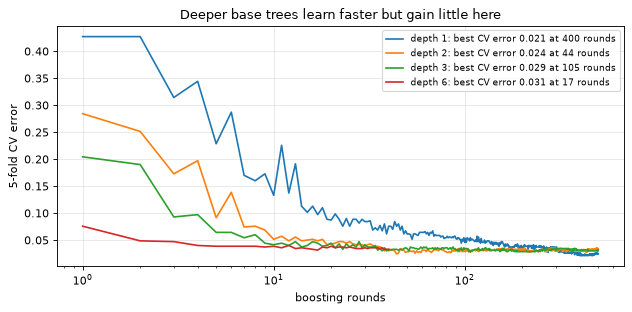

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for depth in [1, 2, 3, 6]:
    curve = cv_staged_error(lambda: stump_ada(500, depth=depth), Xtr, ytr_good)
    best = int(np.argmin(curve)) + 1
    ax.plot(np.arange(1, len(curve) + 1), curve, label=f"depth {depth}: best CV error {curve.min():.3f} at {best} rounds")
    print(f"depth {depth}: CV error after 10 rounds = {curve[9]:.3f}, best = {curve.min():.3f} at round {best}, after {len(curve)} = {curve[-1]:.3f}")
ax.set_xscale("log"); ax.set_xlabel("boosting rounds"); ax.set_ylabel("5-fold CV error"); ax.legend(fontsize=8)
ax.set_title("Deeper base trees learn faster but gain little here")
plt.tight_layout(); plt.show()

> **How to read this**
> * Deeper trees need **far fewer rounds**: after 10 rounds, depth 1 is at 0.133 CV error, depth 3 already at 0.041.
> * But the best errors are close (depth 1: 0.021 at 400 rounds, depth 2: 0.024 at 44, depth 3: 0.029 at 105) and depth 6 is the
>   worst (0.031). Its curve also stops at 40 rounds: in one fold a depth-6 tree classified its weighted training data
>   perfectly (ε = 0), which ends boosting (Lab 12).
> * Stumps are the default for a reason: they can only add one-feature effects, so they are hard to over-fit, and on data
>   like this circle (a sum of one effect per feature) nothing more is needed. If the classes depend on **combinations** of
>   features (Lab 13's XOR), depth ≥ 2 is required.

## Lab 8 · `learning_rate` × `n_estimators`

**Goal:** README §6.2. `learning_rate` (η) multiplies every stage value: α_m = η · (ln((1−ε)/ε) + ln(K−1)). Smaller steps
mean each stump changes the weights less, so more rounds are needed. Grid of 5-fold CV error.

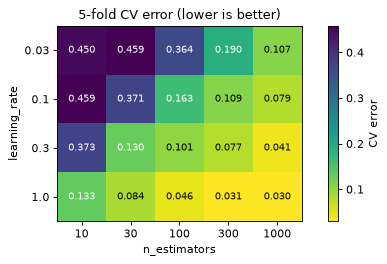

CV error table (rows = learning_rate, columns = n_estimators):
 [[0.45  0.459 0.364 0.19  0.107]
 [0.459 0.371 0.163 0.109 0.079]
 [0.373 0.13  0.101 0.077 0.041]
 [0.133 0.084 0.046 0.031 0.03 ]]


In [12]:
rates = [0.03, 0.1, 0.3, 1.0]
round_grid = [10, 30, 100, 300, 1000]
curves_lr = [cv_staged_error(lambda: stump_ada(1000, learning_rate=lr), Xtr, ytr_good) for lr in rates]   # one CV run per rate
table = np.array([[curve[m - 1] for m in round_grid] for curve in curves_lr])

fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.imshow(table, cmap="viridis_r")
ax.set_xticks(range(len(round_grid)), round_grid); ax.set_yticks(range(len(rates)), rates)
ax.set_xlabel("n_estimators"); ax.set_ylabel("learning_rate"); ax.grid(False)
for i in range(len(rates)):
    for j in range(len(round_grid)):
        ax.text(j, i, f"{table[i, j]:.3f}", ha="center", va="center", color="w" if table[i, j] > 0.12 else "k", fontsize=9)
plt.colorbar(im, ax=ax, label="CV error"); ax.set_title("5-fold CV error (lower is better)")
plt.tight_layout(); plt.show()
print("CV error table (rows = learning_rate, columns = n_estimators):\n", table)

> **How to read this**
> * Read along a row: more rounds help at every learning rate on this clean data.
> * Read down a column: with few rounds, a big learning rate wins (10 rounds: 0.133 at η = 1 vs 0.450 at η = 0.03). With a
>   small η the model simply has not moved far enough yet.
> * Roughly, what matters is **η × rounds**: η = 0.3 with 100 rounds (0.101) is in the same range as η = 1 with 30 rounds
>   (0.084), and η = 0.1 with 1000 rounds (0.079) like η = 1 with 100 (0.046) — the small-η cells are a bit worse, so on this
>   clean data η = 1 is simply best. A smaller η is regularisation (shrinkage): it pays off on **noisy** data (Lab 10), at the
>   price of more rounds.

## Lab 9 · More than two classes: SAMME, and why the rule is ε < 1 − 1/K

**Goal:** README §4.6. Three classes in rings around the centre. A stump has only two leaves, so it can name at most two
of the three classes and often gets more than half of the weight wrong. Binary AdaBoost would give such a stump a
*negative* say; SAMME's extra ln(K − 1) keeps it positive as long as it beats random guessing (ε < 1 − 1/K = 2/3).

class shares: [0.145 0.339 0.515]
first 8 weighted errors eps : [0.485 0.449 0.537 0.514 0.524 0.514 0.517 0.506]
SAMME alpha = ln((1-e)/e) + ln 2: [0.754 0.899 0.547 0.639 0.597 0.638 0.624 0.668]
binary textbook alpha        : [ 0.03   0.103 -0.073 -0.027 -0.048 -0.028 -0.035 -0.013]
rounds with eps > 0.5: 396 of 400;  largest eps = 0.622 (limit 1 - 1/3 = 0.667)
test accuracy: one stump = 0.516, AdaBoost SAMME (400 stumps) = 0.829


SAMME with 400 depth-3 trees = 0.956;  share of test points predicted as the centre class: stumps 0.000, depth 3 0.142 (true 0.144)


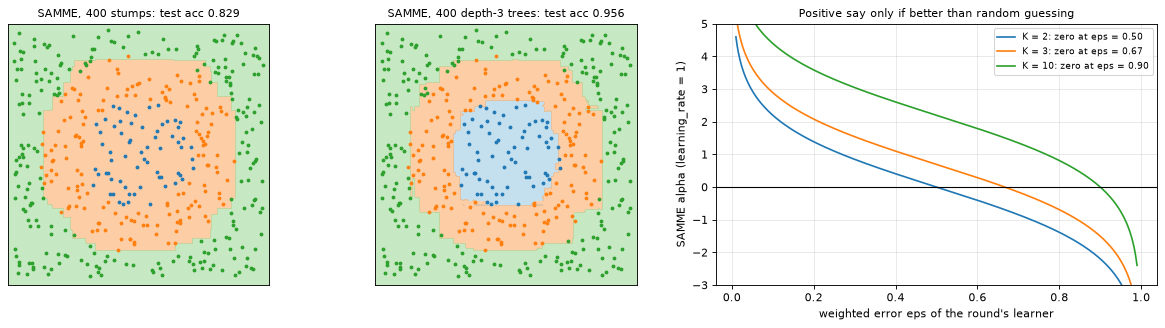

In [13]:
rng = np.random.default_rng(3)
X3 = np.round(rng.uniform(-1, 1, size=(1500, 2)), 3)
r3 = np.sqrt((X3 ** 2).sum(axis=1))
y3 = np.digitize(r3, [0.45, 0.8])                        # 0 = centre, 1 = ring, 2 = outside
X3tr, X3te, y3tr, y3te = train_test_split(X3, y3, test_size=0.3, random_state=0, stratify=y3)

ada3 = stump_ada(400).fit(X3tr, y3tr)
eps3 = ada3.estimator_errors_
print("class shares:", np.bincount(y3) / len(y3))
print("first 8 weighted errors eps :", eps3[:8])
print("SAMME alpha = ln((1-e)/e) + ln 2:", ada3.estimator_weights_[:8])
print("binary textbook alpha        :", (0.5 * np.log((1 - eps3) / eps3))[:8])
print(f"rounds with eps > 0.5: {np.sum(eps3 > 0.5)} of {len(eps3)};  largest eps = {eps3.max():.3f} (limit 1 - 1/3 = {2/3:.3f})")
print(f"test accuracy: one stump = {DecisionTreeClassifier(max_depth=1).fit(X3tr, y3tr).score(X3te, y3te):.3f}, "
      f"AdaBoost SAMME (400 stumps) = {ada3.score(X3te, y3te):.3f}")
ada3_deep = stump_ada(400, depth=3).fit(X3tr, y3tr)
print(f"SAMME with 400 depth-3 trees = {ada3_deep.score(X3te, y3te):.3f};  "
      f"share of test points predicted as the centre class: stumps {np.mean(ada3.predict(X3te) == 0):.3f}, "
      f"depth 3 {np.mean(ada3_deep.predict(X3te) == 0):.3f} (true {np.mean(y3te == 0):.3f})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for ax, model, title in [(axes[0], ada3, "SAMME, 400 stumps"), (axes[1], ada3_deep, "SAMME, 400 depth-3 trees")]:
    plot_regions(ax, model.predict(GRID_POINTS), f"{title}: test acc {model.score(X3te, y3te):.3f}")
    for c, col in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
        ax.scatter(*X3te[y3te == c].T, s=6, c=col)
e = np.linspace(0.01, 0.99, 300)
for K in [2, 3, 10]:
    axes[2].plot(e, np.log((1 - e) / e) + np.log(K - 1), label=f"K = {K}: zero at eps = {1 - 1 / K:.2f}")
axes[2].axhline(0, color="k", lw=1); axes[2].set_ylim(-3, 5)
axes[2].set_xlabel("weighted error eps of the round's learner"); axes[2].set_ylabel("SAMME alpha (learning_rate = 1)")
axes[2].legend(fontsize=8); axes[2].set_title("Positive say only if better than random guessing", fontsize=10)
plt.tight_layout(); plt.show()

> **How to read this**
> * Almost every round has ε above 0.5 (396 of 400; the largest is 0.622). Under the binary formula such a round gets a
>   **negative** α (e.g. ε = 0.537 → α = −0.073): binary AdaBoost would vote *against* it, and the usual rule “stop when ε ≥ ½”
>   would end training at round 3.
> * With K = 3 classes, guessing at random is wrong 2/3 of the time, so ε = 0.537 is still *better than guessing*. SAMME adds
>   ln(K − 1) = ln 2, which moves the zero of α from ε = 0.5 to ε = 1 − 1/K = 0.667 (right plot): that round gets α = +0.547.
> * Result: 400 two-leaf stumps reach test accuracy 0.829 vs 0.516 for one stump. But look at the left map: the stumps never
>   predict the small **centre** class at all (share of test points predicted “centre”: 0.000, true share 0.144; the blue
>   points sit in orange). A stump's two leaves can name only two classes,
>   and a half-plane is never mostly centre-class. Depth-3 trees (middle) do find it: 0.956. Multi-class problems usually
>   need more than stumps (Lab 13).

---
# Part C — Where AdaBoost fails (and why)

## Lab 10 · Noisy labels — the bad-fit dataset

**Goal:** README §8.1. Exponential loss makes AdaBoost multiply the weight of a misclassified point by e^α *every* round it
stays wrong. A flipped label stays wrong (if the model is right about the region). So weight piles up on the 20 %
flipped points, and later rounds are spent chasing them. We track (a) the share of total weight on flipped training
points and (b) the error over rounds, for stumps and for depth-3 trees.

depth 1: rounds [1, 10, 50, 200, 1000, 2000]
   weight share on flipped train points: [0.207 0.286 0.369 0.381 0.399 0.404]  (flipped = 0.207 of the rows)
   train error (noisy labels)          : [0.403 0.27  0.231 0.22  0.226 0.219]
   test error vs noisy labels           : [0.4   0.283 0.237 0.24  0.247 0.243]  best 0.223 at round 20
   test error vs TRUE labels            : [0.383 0.16  0.093 0.09  0.103 0.1  ]  best 0.067 at round 20


depth 3: rounds [1, 10, 50, 200, 1000, 2000]
   weight share on flipped train points: [0.207 0.443 0.427 0.434 0.431 0.422]  (flipped = 0.207 of the rows)
   train error (noisy labels)          : [0.274 0.216 0.183 0.146 0.011 0.   ]
   test error vs noisy labels           : [0.317 0.25  0.25  0.233 0.27  0.28 ]  best 0.233 at round 62
   test error vs TRUE labels            : [0.2   0.1   0.12  0.09  0.153 0.17 ]  best 0.077 at round 62


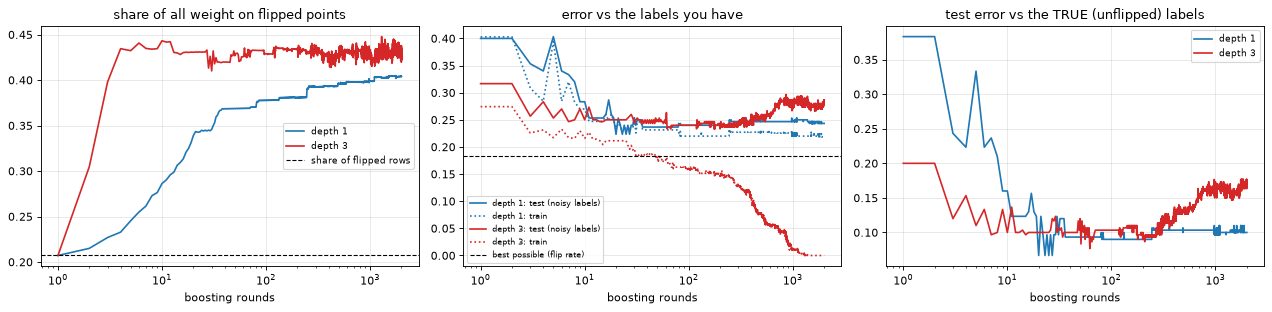

In [14]:
results_noise = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for depth, color in [(1, "tab:blue"), (3, "tab:red")]:
    model = stump_ada(2000, depth=depth).fit(Xtr, ytr_bad)
    W_bad = replay_weights(model, Xtr, ytr_bad)
    share = W_bad[:, flip_tr].sum(axis=1)
    te_noisy, te_clean = staged_errors(model, Xte, yte_bad), staged_errors(model, Xte, yte_good)
    tr_err = staged_errors(model, Xtr, ytr_bad)
    results_noise[depth] = (share, te_noisy, te_clean, tr_err)
    axes[0].plot(np.arange(1, len(share) + 1), share, color=color, label=f"depth {depth}")
    axes[1].plot(np.arange(1, len(te_noisy) + 1), te_noisy, color=color, label=f"depth {depth}: test (noisy labels)")
    axes[1].plot(np.arange(1, len(tr_err) + 1), tr_err, color=color, ls=":", label=f"depth {depth}: train")
    axes[2].plot(np.arange(1, len(te_clean) + 1), te_clean, color=color, label=f"depth {depth}")
    ii = [0, 9, 49, 199, 999, len(share) - 1]
    print(f"depth {depth}: rounds {[i + 1 for i in ii]}")
    print(f"   weight share on flipped train points: {share[ii].round(3)}  (flipped = {flip_tr.mean():.3f} of the rows)")
    print(f"   train error (noisy labels)          : {tr_err[ii].round(3)}")
    print(f"   test error vs noisy labels           : {te_noisy[ii].round(3)}  best {te_noisy.min():.3f} at round {te_noisy.argmin() + 1}")
    print(f"   test error vs TRUE labels            : {te_clean[ii].round(3)}  best {te_clean.min():.3f} at round {te_clean.argmin() + 1}")
axes[0].axhline(flip_tr.mean(), color="k", ls="--", lw=1, label="share of flipped rows")
axes[0].set_title("share of all weight on flipped points"); axes[0].legend(fontsize=8)
axes[1].axhline(flipped[idx_test].mean(), color="k", ls="--", lw=1, label="best possible (flip rate)")
axes[1].set_title("error vs the labels you have"); axes[1].legend(fontsize=7)
axes[2].set_title("test error vs the TRUE (unflipped) labels"); axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("boosting rounds")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: flipped points are 20.7 % of the training rows, but they soon hold about **twice that share** of the weight: with
>   stumps 28.6 % after 10 rounds, 36.9 % after 50 and 40.4 % after 2000; with depth-3 trees 44 % already after 10 rounds.
>   AdaBoost spends a big part of its attention on rows whose labels are wrong.
> * Middle, depth 3 (red): the training error (dotted) falls to 0.000 by round 2000 — the model has **memorised every flipped
>   label** — while the test error **rises** from its best, 0.233 at round 62, to 0.280. More rounds make it worse.
> * Stumps (blue) cannot carve out single points, so their error against the noisy labels mostly plateaus (best 0.223 at
>   round 20, 0.243 at round 2000). The right panel (error against the true circle, which we know only because we made the data)
>   shows the damage plainly for both: stumps 0.067 → 0.100, depth 3 0.077 → 0.170.

In [15]:
cv_bad_1 = cv_staged_error(lambda: stump_ada(2000), Xtr, ytr_bad)
cv_bad_3 = cv_staged_error(lambda: stump_ada(2000, depth=3), Xtr, ytr_bad)
m1, m3 = int(np.argmin(cv_bad_1)) + 1, int(np.argmin(cv_bad_3)) + 1
print(f"rounds chosen by 5-fold CV on the noisy training set: stumps {m1}, depth-3 {m3}")

fixes = {
    "AdaBoost depth 3, 2000 rounds (no care)": stump_ada(2000, depth=3),
    f"AdaBoost depth 3, early stop at {m3} (CV)": stump_ada(m3, depth=3),
    "AdaBoost depth 3, learning_rate 0.1, 2000": stump_ada(2000, learning_rate=0.1, depth=3),
    "AdaBoost stumps, 2000 rounds": stump_ada(2000),
    f"AdaBoost stumps, early stop at {m1} (CV)": stump_ada(m1),
    "gradient boosting, log-loss (default)": GradientBoostingClassifier(random_state=0),
    "random forest, min_samples_leaf=5": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=0, n_jobs=-1),
}
print(f"\n{'model':44s} test err (noisy)  test err (true labels)")
for name, model in fixes.items():
    pred = model.fit(Xtr, ytr_bad).predict(Xte)
    print(f"{name:44s} {np.mean(pred != yte_bad):.3f}            {np.mean(pred != yte_good):.3f}")

rounds chosen by 5-fold CV on the noisy training set: stumps 149, depth-3 46

model                                        test err (noisy)  test err (true labels)


AdaBoost depth 3, 2000 rounds (no care)      0.280            0.170
AdaBoost depth 3, early stop at 46 (CV)      0.250            0.100


AdaBoost depth 3, learning_rate 0.1, 2000    0.233            0.090


AdaBoost stumps, 2000 rounds                 0.243            0.100
AdaBoost stumps, early stop at 149 (CV)      0.240            0.090
gradient boosting, log-loss (default)        0.240            0.103


random forest, min_samples_leaf=5            0.227            0.070


> **How to read this**
> * The careless configuration (depth 3, 2000 rounds) is the worst: 0.280 test error against the labels and 0.170
>   against the truth.
> * Every fix helps. **Early stopping** at the number of rounds chosen by CV on the training set (46 for depth 3, 149 for stumps)
>   gives 0.250 / 0.100 and 0.240 / 0.090; a **smaller learning rate** (0.1) gives 0.233 / 0.090. **Log-loss gradient boosting**
>   (0.240 / 0.103) and a **random forest** with slightly bigger leaves (0.227 / 0.070, the best here) do not have the
>   exponential weight explosion: log-loss grows only *linearly* for badly wrong points (README §4.7), and a forest does not
>   re-weight at all.
> * The floor is the 18.3 % of flipped test labels: no model can predict a coin flip.

## Lab 11 · Outliers: in the features (harmless) vs in the labels (harmful)

**Goal:** README §8.2, the old “outliers force the ensemble down the rabbit hole” advice, made precise. Two experiments on
the clean training set:

* **Feature outliers:** push 10 training points 10× further out (`x × 10`) but keep their correct labels.
* **Label outliers:** relabel 10 points deep inside the circle (`r < 0.3`) as class 0 — points that look like the
  centre but carry the wrong class.

clean training data            : test accuracy 0.967
10 feature outliers (x10)      : test accuracy 0.970
10 label outliers in the centre: test accuracy 0.920
   round   1: the 10 label outliers (1.4% of rows) hold 1.4% of the weight
   round  10: the 10 label outliers (1.4% of rows) hold 3.0% of the weight
   round 100: the 10 label outliers (1.4% of rows) hold 16.7% of the weight
   round 800: the 10 label outliers (1.4% of rows) hold 21.0% of the weight


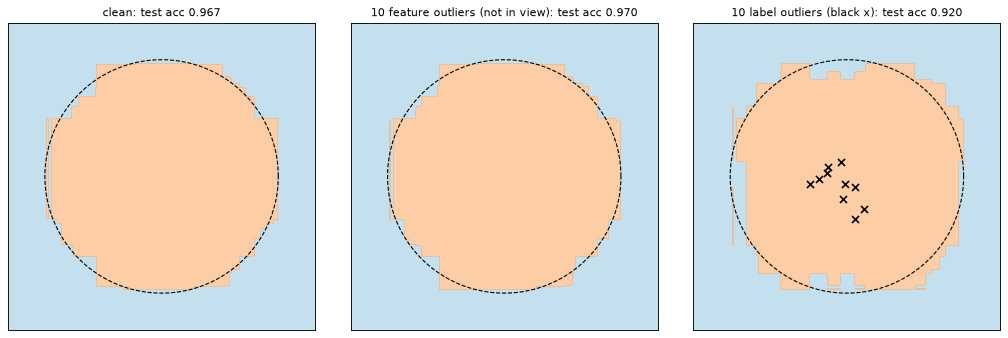

In [16]:
rng = np.random.default_rng(7)
far = rng.choice(len(Xtr), 10, replace=False)
X_far = Xtr.copy(); X_far[far] *= 10
inside = np.flatnonzero(np.sqrt((Xtr ** 2).sum(axis=1)) < 0.3)[:10]
y_lab = ytr_good.copy(); y_lab[inside] = 0

base = stump_ada(800).fit(Xtr, ytr_good)
ada_far = stump_ada(800).fit(X_far, ytr_good)
ada_lab = stump_ada(800).fit(Xtr, y_lab)
W_lab = replay_weights(ada_lab, Xtr, y_lab)
print(f"clean training data            : test accuracy {base.score(Xte, yte_good):.3f}")
print(f"10 feature outliers (x10)      : test accuracy {ada_far.score(Xte, yte_good):.3f}")
print(f"10 label outliers in the centre: test accuracy {ada_lab.score(Xte, yte_good):.3f}")
for m in [1, 10, 100, 800]:
    print(f"   round {m:3d}: the 10 label outliers ({10 / len(Xtr):.1%} of rows) hold {W_lab[m - 1][inside].sum():.1%} of the weight")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, model, title in [(axes[0], base, "clean"), (axes[1], ada_far, "10 feature outliers (not in view)"), (axes[2], ada_lab, "10 label outliers (black x)")]:
    plot_regions(ax, model.predict(GRID_POINTS), f"{title}: test acc {model.score(Xte, yte_good):.3f}")
    draw_circle(ax)
axes[2].scatter(*Xtr[inside].T, marker="x", c="k", s=40)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Feature outliers do not matter** (test accuracy 0.967 → 0.970). A stump only asks “is x1 ≤ t?”, so moving a point from
>   0.9 to 9.0 changes nothing except which side of a far-out threshold it falls on; the *order* of the points, which is all a
>   tree uses, hardly changes. (Very different from methods built on distances or squares, such as PCA or linear regression.)
> * **Label outliers do matter**: the 10 relabelled points are 1.4 % of the rows but hold 16.7 % of all the weight by round 100
>   and 21.0 % by round 800. Stumps cannot cut a hole in the middle of the circle, so the chase shows up as notches and stripes
>   along the edge of the circle (right map), and test accuracy drops to 0.920.
> * So the old advice is right in spirit: clean your **labels**, and look hard at points whose label is implausible for where
>   they sit. Extreme *feature* values are not the problem for tree-based AdaBoost.

## Lab 12 · A too-strong base learner: boosting stops after one round

**Goal:** README §8.3. AdaBoost needs learners that make mistakes. A fully grown tree fits its training data perfectly,
so ε₁ = 0: there is nothing to re-weight, and scikit-learn stops after the first round.

In [17]:
for name, y_train, y_test in [("good fit", ytr_good, yte_good), ("bad fit", ytr_bad, yte_bad)]:
    deep = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=None, random_state=0), n_estimators=50, random_state=0)
    deep.fit(Xtr, y_train)
    single = DecisionTreeClassifier(random_state=0).fit(Xtr, y_train)
    print(f"{name}: trees actually fitted = {len(deep.estimators_)} of 50;  estimator_errors_[:3] = {deep.estimator_errors_[:3]};"
          f"  estimator_weights_[:3] = {deep.estimator_weights_[:3]}")
    same = np.array_equal(deep.predict(Xte), deep.estimators_[0].predict(Xte))
    print(f"   test accuracy AdaBoost(deep tree) = {deep.score(Xte, y_test):.3f};  identical to its one tree's predictions: {same};"
          f"  a separately grown deep tree = {single.score(Xte, y_test):.3f}")

good fit: trees actually fitted = 1 of 50;  estimator_errors_[:3] = [0. 1. 1.];  estimator_weights_[:3] = [1. 0. 0.]
   test accuracy AdaBoost(deep tree) = 0.963;  identical to its one tree's predictions: True;  a separately grown deep tree = 0.963
bad fit: trees actually fitted = 1 of 50;  estimator_errors_[:3] = [0. 1. 1.];  estimator_weights_[:3] = [1. 0. 0.]
   test accuracy AdaBoost(deep tree) = 0.690;  identical to its one tree's predictions: True;  a separately grown deep tree = 0.680


> **How to read this**
> * Only **1** of the 50 requested trees was fitted. Its weighted error is exactly 0, its weight is set to 1, and the
>   unused slots keep their initial values (errors 1, weights 0).
> * So the “ensemble” is just one deep tree: its predictions are identical to that tree's (True), on the noisy data a tree that
>   memorised every flipped label (test accuracy 0.690). Nothing was boosted. (A separately grown deep tree scores 0.680 only
>   because it broke ties between equally good splits differently.) Use shallow trees (depth 1–3) for boosting, or bagging /
>   random forests for deep trees.

## Lab 13 · A too-weak base learner: XOR, and ten classes

**Goal:** README §8.4. (a) If **no** stump beats random guessing, AdaBoost cannot even start. The classic case is XOR: four
equal clusters where the class depends on *both* features together. (b) With many classes a stump's two leaves can name only
two of them, so each round learns little.

In [18]:
corners = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]], dtype=float)
offsets = np.random.default_rng(0).uniform(-0.5, 0.5, size=(25, 2))
X_xor = np.vstack([c + offsets for c in corners])                 # the same 25 offsets in every corner
y_xor = np.repeat([0, 1, 1, 0], 25)                              # class 1 when exactly one coordinate is positive
try:
    stump_ada(50).fit(X_xor, y_xor)
except ValueError as err:
    print("stumps on XOR -> ValueError:", err)
print("best single stump's error on XOR:", 1 - DecisionTreeClassifier(max_depth=1).fit(X_xor, y_xor).score(X_xor, y_xor))
print("depth-2 trees on XOR, training accuracy:", stump_ada(50, depth=2).fit(X_xor, y_xor).score(X_xor, y_xor))

X_dig, y_dig = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_dig, y_dig, test_size=0.3, random_state=0, stratify=y_dig)
print("\nhandwritten digits, K = 10 classes, 300 rounds:")
for depth in [1, 2, 4]:
    model = stump_ada(300, depth=depth).fit(Xd_tr, yd_tr)
    print(f"   depth {depth}: test accuracy {model.score(Xd_te, yd_te):.3f};  first 3 weighted errors {model.estimator_errors_[:3]} (limit 0.9)")

stumps on XOR -> ValueError: BaseClassifier in AdaBoostClassifier ensemble is worse than random, ensemble can not be fit.
best single stump's error on XOR: 0.5
depth-2 trees on XOR, training accuracy: 1.0

handwritten digits, K = 10 classes, 300 rounds:


   depth 1: test accuracy 0.848;  first 3 weighted errors [0.802 0.778 0.747] (limit 0.9)


   depth 2: test accuracy 0.950;  first 3 weighted errors [0.683 0.619 0.557] (limit 0.9)


   depth 4: test accuracy 0.987;  first 3 weighted errors [0.41 0.24 0.3 ] (limit 0.9)


> **How to read this**
> * **XOR:** by symmetry every stump is right on exactly half of the weight (best error 0.5 = 1 − 1/K), so the very first
>   round already fails the rule ε < 1 − 1/K and scikit-learn raises *“…worse than random, ensemble can not be fit.”*
>   A sum of one-feature steps can never express “x1 and x2 have different signs”. Depth-2 trees can (training accuracy 1.0).
> * **Digits:** stumps have weighted errors around 0.8 (0.802, 0.778, 0.747) — fine for SAMME (limit 1 − 1/10 = 0.9),
>   impossible for binary AdaBoost (limit 0.5) — but each round tells apart only two groups of digits. 300 stumps reach 0.848
>   test accuracy; depth-2 trees 0.950; depth-4 trees 0.987. Match the base learner to the problem: more classes or
>   interacting features → deeper trees.

## Lab 14 · `predict_proba` is poorly calibrated

**Goal:** README §8.5. A probability is **calibrated** if, of all points that get “0.8”, about 80 % really are class 1.
scikit-learn turns AdaBoost's normalised score f = Σα h / Σα (between −1 and 1) into p = 1 / (1 + e^(−2f)), so for two
classes it can never say more than 1/(1 + e^(−2)) = 0.881. We compare a reliability curve and two probability scores
(Brier score and log-loss, both lower = better) with a calibrated version and gradient boosting, on the clean good-fit data.

model                        accuracy  Brier   log-loss  min p   max p
AdaBoost predict_proba       0.967     0.191   0.574     0.322   0.609


AdaBoost + isotonic (CV)     0.967     0.023   0.195     0.000   1.000
gradient boosting            0.953     0.034   0.113     0.000   0.996


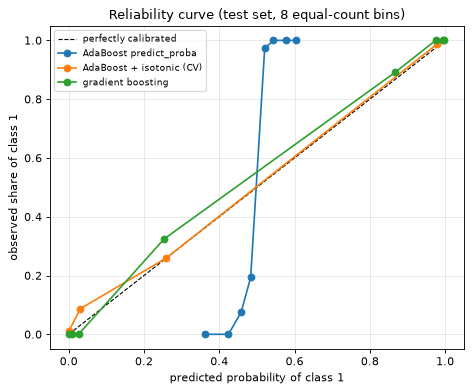

In [19]:
ada_p = stump_ada(800).fit(Xtr, ytr_good)
ada_cal = CalibratedClassifierCV(stump_ada(800), method="isotonic", cv=5).fit(Xtr, ytr_good)   # calibrated on CV folds of TRAIN
gb_p = GradientBoostingClassifier(random_state=0).fit(Xtr, ytr_good)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
print(f"{'model':28s} accuracy  Brier   log-loss  min p   max p")
for name, model in [("AdaBoost predict_proba", ada_p), ("AdaBoost + isotonic (CV)", ada_cal), ("gradient boosting", gb_p)]:
    p = model.predict_proba(Xte)[:, 1]
    frac, mean_p = calibration_curve(yte_good, p, n_bins=8, strategy="quantile")
    ax.plot(mean_p, frac, "o-", label=name)
    print(f"{name:28s} {model.score(Xte, yte_good):.3f}     {brier_score_loss(yte_good, p):.3f}   {log_loss(yte_good, p):.3f}     {p.min():.3f}   {p.max():.3f}")
ax.set_xlabel("predicted probability of class 1"); ax.set_ylabel("observed share of class 1"); ax.legend(fontsize=8)
ax.set_title("Reliability curve (test set, 8 equal-count bins)")
plt.tight_layout(); plt.show()

> **How to read this**
> * AdaBoost's **classifications** are excellent (accuracy 0.967), but its **probabilities** are squeezed into 0.322–0.609:
>   the blue curve is almost vertical — points it calls “0.45” are nearly all class 0, points it calls “0.55” nearly all class 1.
>   Its Brier score (0.191) and log-loss (0.574) are far worse than the calibrated version's (0.023, 0.195) at the same accuracy.
> * Why: the score is a weighted average of ±1 votes; after hundreds of rounds many stumps disagree with each other, so the
>   average sits near 0 even for easy points. The *ordering* (which point is more likely class 1) is good; the *scale* is not.
> * Fix: wrap the model in `CalibratedClassifierCV` (fitted on cross-validation folds of the training data, not the test
>   set), or use a model trained on log-loss when you need probabilities: gradient boosting gets Brier 0.034 and the best
>   log-loss, 0.113. (Isotonic calibration's log-loss is higher than its Brier score suggests because it sometimes says exactly
>   0 or 1, and log-loss punishes a confident miss heavily.)

## Lab 15 · Sequential training: rounds cannot run in parallel

**Goal:** README §8.6. Round m's weights depend on round m − 1's stump, so AdaBoost's rounds must run one after another
(scikit-learn's `AdaBoostClassifier` has no `n_jobs`). A random forest's trees are independent and can be spread over all
CPU cores. Timings on 20 000 circle points (your numbers will differ by machine; the *ratios* are the point).

In [20]:
rng = np.random.default_rng(11)
X_big = rng.uniform(-1, 1, size=(20_000, 2))
y_big = (X_big[:, 0] ** 2 + X_big[:, 1] ** 2 < 2 / np.pi).astype(int)
timings = {}
for name, make in [("AdaBoost stumps", lambda n: stump_ada(n)),
                   ("AdaBoost depth 3", lambda n: stump_ada(n, depth=3)),
                   ("random forest, 1 core", lambda n: RandomForestClassifier(n_estimators=n, max_depth=3, random_state=0, n_jobs=1)),
                   ("random forest, all cores", lambda n: RandomForestClassifier(n_estimators=n, max_depth=3, random_state=0, n_jobs=-1))]:
    for n in [50, 200, 800]:
        t0 = time.perf_counter(); make(n).fit(X_big, y_big); timings[(name, n)] = time.perf_counter() - t0
    print(f"{name:26s} fit time for 50 / 200 / 800 trees: " + " / ".join(f"{timings[(name, n)]:.2f}s" for n in [50, 200, 800]))

AdaBoost stumps            fit time for 50 / 200 / 800 trees: 0.19s / 0.74s / 2.98s


AdaBoost depth 3           fit time for 50 / 200 / 800 trees: 0.46s / 1.83s / 7.13s


random forest, 1 core      fit time for 50 / 200 / 800 trees: 0.19s / 0.74s / 2.88s


random forest, all cores   fit time for 50 / 200 / 800 trees: 0.05s / 0.18s / 0.65s


> **How to read this**
> * AdaBoost's time grows in proportion to the number of rounds (stumps: about 0.2 s → 0.75 s → 3 s for 50 → 200 → 800 on the
>   machine that executed this notebook; your numbers will differ a little on every run), and more cores cannot help: each round
>   needs the previous round's weights.
> * A random forest with the same number of depth-3 trees takes about as long on one core (about 3 s for 800), but its trees
>   are independent, so `n_jobs=-1` runs them in parallel: under 1 s, roughly 3–4× faster here.
> * For a few hundred stumps this is seconds, not a problem. It becomes one on large data with many rounds — that is where
>   histogram-based gradient boosting (`HistGradientBoostingClassifier`, XGBoost) is usually preferred: still sequential
>   across rounds, but each round is much cheaper and is parallelised inside.

---
# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| 1 | The hand example: ε = 1/8, 1/7, 5/24; α = ½ ln 7, ½ ln 6, ½ ln(19/5); all 8 points right after 3 stumps; sklearn's α is 2× with the same weights and predictions | ✔ same numbers |
| 2 | Misclassified points gain weight; the weight concentrates near the boundary | ✔ |
| 3 | A weighted sum of stumps builds an axis-aligned staircase boundary | ✔ |
| 4 | Training error ≤ ∏ 2√(ε(1−ε)), which equals the training exponential loss | ✔ exactly |
| 5 | After training error hits 0, margins keep growing and test error keeps falling | ✔ |
| 6 | Boosting stumps gives a strong model (one stump 0.670 → AdaBoost 0.970 test accuracy) | ✔ |
| 7 | Deeper base trees need fewer rounds; too deep leaves nothing to boost | ✔ |
| 8 | Smaller `learning_rate` needs more rounds | ✔ |
| 9 | SAMME: ε may exceed ½ for K > 2; α > 0 iff ε < 1 − 1/K | ✔ |
| 10 | ✘ Noisy labels: weight piles onto flipped points; test error rises with rounds (deeper trees) | failure shown |
| 11 | ✘ Label outliers attract weight and distort the boundary (feature outliers do not) | failure shown |
| 12 | ✘ A perfect base learner (ε = 0) stops boosting after one round | failure shown |
| 13 | ✘ A learner no better than chance (XOR) cannot start; stumps are weak for 10 classes | failure shown |
| 14 | ✘ `predict_proba` is squeezed towards 0.5 and badly calibrated | failure shown |
| 15 | ✘ Rounds are sequential; training cannot be spread over cores (a forest gets ~3–4× from `n_jobs=-1`) | failure shown |